In [1]:

# ==========================================
# PROJECT 3 - ALL LIBRARIES IMPORT
# ==========================================

# Data Handling
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Data Preprocessing
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Data Splitting
from sklearn.model_selection import train_test_split

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Machine Learning Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Handling Imbalanced Data
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE, ADASYN

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Model Evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

# Model Evaluation Visualization
from sklearn.metrics import ConfusionMatrixDisplay

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Visualization Theme
sns.set_theme(style="whitegrid")


from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE, ADASYN
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [2]:

# =====================================================
# 📊 PROJECT 3 - FINAL PLOT SAVING SYSTEM
# =====================================================

import matplotlib.pyplot as plt
import os

# Exact Project Folder
project_root = r"D:\Supervised Learning\Projects\Project 3"

# Plot Folder
plot_folder = os.path.join(
    project_root,
    "Final_Output",
    "All_Plots"
)

# Create Folder
os.makedirs(plot_folder, exist_ok=True)

# Original Matplotlib Show
original_show = plt.show

# Plot Counter
plot_counter = 0

# Save Every Plot Automatically
def save_project_plot(*args, **kwargs):

    global plot_counter

    os.makedirs(plot_folder, exist_ok=True)

    for fig_num in plt.get_fignums():

        fig = plt.figure(fig_num)

        plot_counter += 1

        filename = "Plot_" + str(plot_counter).zfill(3) + ".png"

        filepath = os.path.join(plot_folder, filename)

        fig.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        print("Successfully Saved:", filepath)

    return original_show(*args, **kwargs)


plt.show = save_project_plot

print("PLOT SAVING SYSTEM READY")
print("Folder Exists:", os.path.isdir(plot_folder))
print("Saving Location:", plot_folder)


PLOT SAVING SYSTEM READY
Folder Exists: True
Saving Location: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots



# 🧠 PART A: CONCEPTUAL UNDERSTANDING (THEORY)

---
**Objective:** Understand the fundamental concepts of classification, 
Logistic Regression, evaluation metrics, and imbalanced datasets.

**Total Tasks:** 6
**Project:** Risk Alert Classifier
---



### 📌 Task 1: What is Logistic Regression and why is it suitable for classification?

Logistic Regression is a supervised machine learning algorithm used for classification problems. It predicts the probability of a class using the sigmoid function and is suitable for binary classification problems.



### 📌 Task 2: Explain classification performance metrics and why accuracy alone is insufficient.

Classification performance metrics are used to evaluate how well a model predicts classes. Accuracy alone is insufficient for imbalanced datasets because it may give high scores even when the model fails to identify the minority class.



### 📌 Task 3: Define Type-I Error and Type-II Error in the context of risk prediction.

- **Type-I Error:** Predicting a customer as High Risk when the customer is actually Low Risk (False Positive).
- **Type-II Error:** Predicting a customer as Low Risk when the customer is actually High Risk (False Negative).



### 📌 Task 4: Explain Precision, Recall, F1-Score, TPR, and FPR.

- **Precision:** Correct positive predictions out of all positive predictions.
- **Recall (TPR):** Correct positive predictions out of all actual positive cases.
- **F1-Score:** Harmonic mean of Precision and Recall.
- **TPR:** True Positive Rate, same as Recall.
- **FPR:** False Positive Rate, the proportion of actual negative cases incorrectly predicted as positive.



### 📌 Task 5: What is AUC-ROC and how does it help in evaluating classifiers?

AUC-ROC measures how well a classification model distinguishes between different classes. ROC represents True Positive Rate against False Positive Rate, while AUC measures the overall performance. A higher AUC indicates better classification ability.



### 📌 Task 6: Why does imbalanced data create problems in classification models?

Imbalanced data occurs when one class has significantly more records than another class. The model may become biased towards the majority class and fail to identify minority class examples correctly, resulting in poor predictions.



---

### 📝 PART A: CONCLUSION

In this part, we understood the basic concepts of Logistic Regression, classification metrics, Type-I and Type-II errors, and AUC-ROC. We also learned how imbalanced data affects classification model performance.

---



# ✅ PART A COMPLETED SUCCESSFULLY

**Status:** All 6 theoretical tasks completed.

**Next:** 📊 Part B – Dataset Understanding & Preparation



# 🧪 PART B: DATASET UNDERSTANDING & PREPARATION

---

**🎯 Objective:**

Understand customer demographic information, transaction activity indicators, credit behavior indicators, and prepare the dataset for classification.

**📂 Dataset:** Risk_Alert_Classifier_Dataset_4600.csv

**🎯 Target Variable:** risk_status

- 0 → Low Risk
- 1 → High Risk

**📌 Total Tasks:** 3 (Task 7, 8 and 9)

---



### 📌 Task 7: Identify Input Features and Target Variable

Input features (X) are the independent variables used to predict customer risk. The target variable (y) is `risk_status`, which represents Low Risk (0) and High Risk (1).

The `customer_id` column is excluded because it is only used to identify customers.


In [3]:

# 📊 Task 7: Identify Input Features and Target Variable

# Load Dataset According to Folder Structure
df = pd.read_csv("../Dataset/Risk_Alert_Classifier_Dataset_4600.csv")

# Separate Input Features and Target Variable
X = df.drop(columns=["customer_id", "risk_status"])
y = df["risk_status"]

# Display Dataset Information
print("Dataset Shape:", df.shape)

print("\nInput Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nTarget Distribution:")
print(y.value_counts())


Dataset Shape: (4600, 19)

Input Features Shape: (4600, 17)
Target Variable Shape: (4600,)

Input Features:
['age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr']

Target Variable:
risk_status

Target Distribution:
risk_status
0    4043
1     557
Name: count, dtype: int64



### 📌 Task 8: Perform a Train-Test Split

The dataset is divided into 80% training data and 20% testing data. Stratified splitting maintains the original class distribution in both datasets and helps evaluate the classification model fairly.


In [4]:

# 📊 Task 8: Stratified Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display Dataset Shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Check Class Distribution
print("\nOriginal Class Distribution:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nTraining Class Distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Class Distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Training Features: (3680, 17)
Testing Features: (920, 17)

Training Target: (3680,)
Testing Target: (920,)

Original Class Distribution:
risk_status
0    87.89
1    12.11
Name: proportion, dtype: float64

Training Class Distribution:
risk_status
0    87.88
1    12.12
Name: proportion, dtype: float64

Testing Class Distribution:
risk_status
0    87.93
1    12.07
Name: proportion, dtype: float64



### 📌 Task 9: Identify Missing Values and Apply KNN Imputer

Missing values can affect machine learning model performance. KNN Imputer fills missing numerical values using information from the five nearest records. StandardScaler is applied before imputation to make distance calculations more balanced.

The imputer is fitted only on training data to prevent data leakage.


In [5]:

# 📊 Task 9: Identify Missing Values

# Check Missing Values
print("Missing Values in Dataset:")

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Separate Numerical Columns
numerical_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical Columns:")
print(numerical_columns)

print("\nTotal Numerical Columns:", len(numerical_columns))


Missing Values in Dataset:
age                         140
region                      102
employment_type             144
annual_income_inr           166
credit_score                216
credit_utilization_ratio    147
monthly_spend_inr           129
dtype: int64

Total Missing Values: 1044

Numerical Columns:
['age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr']

Total Numerical Columns: 13


In [6]:

# 📊 Apply KNN Imputer

# Scale Numerical Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test_scaled = scaler.transform(
    X_test[numerical_columns]
)

# Apply KNN Imputer
knn_imputer = KNNImputer(n_neighbors=5)

X_train_imputed = knn_imputer.fit_transform(
    X_train_scaled
)

X_test_imputed = knn_imputer.transform(
    X_test_scaled
)

# Convert Imputed Data Back to Original Scale
X_train_prepared = X_train.copy()
X_test_prepared = X_test.copy()

X_train_prepared[numerical_columns] = scaler.inverse_transform(
    X_train_imputed
)

X_test_prepared[numerical_columns] = scaler.inverse_transform(
    X_test_imputed
)

print("KNN Imputation Completed Successfully!")


KNN Imputation Completed Successfully!


In [7]:

# 📊 Verify Imputation Results

print("Training Numerical Missing Values:",
      X_train_prepared[numerical_columns].isnull().sum().sum())

print("Testing Numerical Missing Values:",
      X_test_prepared[numerical_columns].isnull().sum().sum())

print("\nTraining Dataset Shape:", X_train_prepared.shape)
print("Testing Dataset Shape:", X_test_prepared.shape)

print("\nRemaining Categorical Missing Values:")

categorical_columns = X_train_prepared.select_dtypes(
    exclude=np.number
).columns

print(X_train_prepared[categorical_columns].isnull().sum())

print("\nKNN Imputation Verification Completed!")


Training Numerical Missing Values: 0
Testing Numerical Missing Values: 0

Training Dataset Shape: (3680, 17)
Testing Dataset Shape: (920, 17)

Remaining Categorical Missing Values:
gender                     0
region                    78
employment_type          115
last_transaction_date      0
dtype: int64

KNN Imputation Verification Completed!



### 📝 PART B: CONCLUSION

In this part, we identified the input features and target variable, performed an 80:20 stratified train-test split, and handled missing numerical values using KNN Imputer. The training and testing datasets are now prepared for further classification preprocessing.



# ✅ PART B COMPLETED SUCCESSFULLY

**Tasks Completed:** 7, 8 and 9

**Dataset Preparation:** Completed

**Next:** 🤖 Part C – Baseline Classification Model

---



# 📊 PART C: BASELINE CLASSIFICATION MODEL

---

**🎯 Objective:**

Build a baseline classification model using Logistic Regression to predict customer risk status.

**🤖 Algorithm:** Logistic Regression

**Target Classes:**
- 0 → Low Risk
- 1 → High Risk

**Evaluation:** Confusion Matrix, Accuracy, Precision, Recall and F1-Score.

---



### 📌 Task 10: Implement Logistic Regression as a Baseline Model

Logistic Regression is used as a baseline classification algorithm to predict whether a customer belongs to the Low Risk or High Risk category. The model is trained using the training dataset and evaluated using unseen testing data.


In [8]:

# 🤖 Task 10: Logistic Regression Baseline Model

# Prepare Training and Testing Features
X_train_model = X_train_prepared.drop(
    columns=["last_transaction_date"],
    errors="ignore"
)

X_test_model = X_test_prepared.drop(
    columns=["last_transaction_date"],
    errors="ignore"
)

# Identify Numerical and Categorical Columns
numerical_columns = X_train_model.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train_model.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical Preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical Preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine Preprocessing Steps
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# Create Logistic Regression Pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train Model
logistic_model.fit(X_train_model, y_train)

# Make Predictions
y_pred = logistic_model.predict(X_test_model)

print("Logistic Regression Model Trained Successfully!")
print("Training Records:", X_train_model.shape[0])
print("Testing Records:", X_test_model.shape[0])


Logistic Regression Model Trained Successfully!
Training Records: 3680
Testing Records: 920



### 📌 Task 11: Generate and Interpret Classification Metrics

The trained model is evaluated using a Confusion Matrix and classification performance metrics. Accuracy measures overall correctness, while Precision, Recall and F1-Score help evaluate the model's ability to identify High Risk customers.


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_001.png


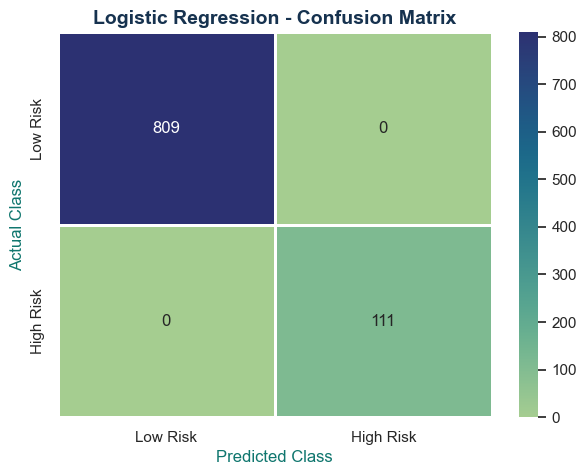

In [9]:

# 📊 Task 11: Generate Confusion Matrix

# Calculate Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="crest",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"],
    linewidths=1
)

plt.title("Logistic Regression - Confusion Matrix",
          color="#16324F", fontsize=14, fontweight="bold")

plt.xlabel("Predicted Class", color="#0F766E")
plt.ylabel("Actual Class", color="#0F766E")
plt.show()


In [10]:

# 📈 Calculate Classification Performance Metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

# Display Results
print("LOGISTIC REGRESSION - MODEL PERFORMANCE")
print("-" * 45)

print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))


LOGISTIC REGRESSION - MODEL PERFORMANCE
---------------------------------------------
Accuracy  : 1.0
Precision : 1.0
Recall    : 1.0
F1-Score  : 1.0


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_002.png


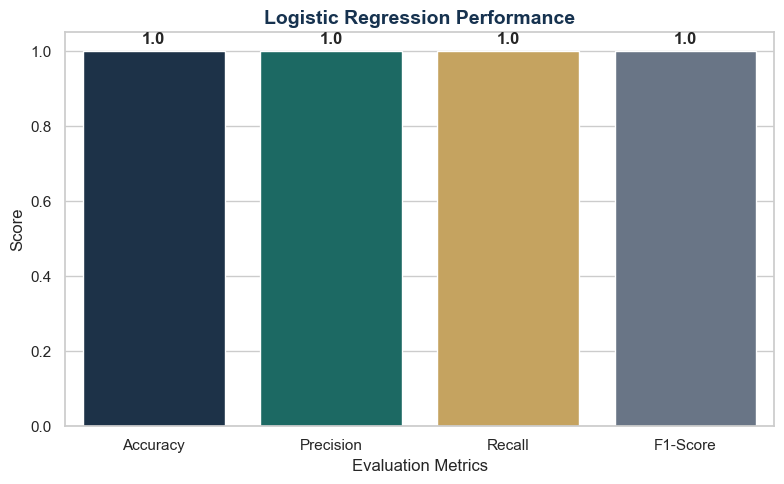


Classification Report:
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [11]:

# 📊 Visualize Model Performance

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=metrics,
    x="Metric",
    y="Score",
    hue="Metric",
    palette=["#16324F", "#0F766E", "#D6A84F", "#64748B"],
    legend=False
)

plt.title("Logistic Regression Performance",
          color="#16324F", fontsize=14, fontweight="bold")

plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.05)

for i, value in enumerate(metrics["Score"]):
    plt.text(i, value + 0.02, round(value, 3),
             ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Low Risk", "High Risk"],
    zero_division=0
))



### 📌 Task 12: Identify Type-I and Type-II Errors

Type-I and Type-II errors are identified using the Confusion Matrix.

- **Type-I Error (False Positive):** A Low Risk customer is incorrectly predicted as High Risk.
- **Type-II Error (False Negative):** A High Risk customer is incorrectly predicted as Low Risk.

These errors help us understand the incorrect predictions made by the classification model.


In [12]:

# 📊 Task 12: Identify Type-I and Type-II Errors

# Extract Confusion Matrix Values
TN, FP, FN, TP = cm.ravel()

print("CONFUSION MATRIX ERROR ANALYSIS")
print("-" * 40)

print("True Negative (TN) :", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP) :", TP)

print("\nTYPE-I ERROR (False Positive):")
print("Low Risk predicted as High Risk:", FP)

print("\nTYPE-II ERROR (False Negative):")
print("High Risk predicted as Low Risk:", FN)

print("\nError Identification Completed!")


CONFUSION MATRIX ERROR ANALYSIS
----------------------------------------
True Negative (TN) : 809
False Positive (FP): 0
False Negative (FN): 0
True Positive (TP) : 111

TYPE-I ERROR (False Positive):
Low Risk predicted as High Risk: 0

TYPE-II ERROR (False Negative):
High Risk predicted as Low Risk: 0

Error Identification Completed!



### 📝 PART C: CONCLUSION

In this part, we implemented Logistic Regression as a baseline classification model. We evaluated its performance using the Confusion Matrix, Accuracy, Precision, Recall and F1-Score. We also identified Type-I and Type-II errors to understand incorrect risk predictions.



# ✅ PART C COMPLETED SUCCESSFULLY

**Tasks Completed:** 10, 11 and 12

**Baseline Model:** Logistic Regression

**Next:** ⚖️ Part D – Handling Imbalanced Data

---



# ⚖️ PART D: HANDLING IMBALANCED DATA

---

**🎯 Objective:**

Understand the impact of class imbalance on classification performance and improve minority class prediction using different balancing techniques.

**📌 Target Variable:** risk_status

- 0 → Low Risk
- 1 → High Risk

**📌 Total Tasks:** 3 (Task 13, 14 and 15)

---



### 📌 Task 13: Demonstrate the Impact of Class Imbalance on Model Performance

An imbalanced dataset contains unequal numbers of records in different classes. In this dataset, Low Risk customers are much higher than High Risk customers. This can make the model biased towards the majority class and reduce its ability to identify High Risk customers.


Training Class Distribution:
risk_status
0    3234
1     446
Name: count, dtype: int64
Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_003.png


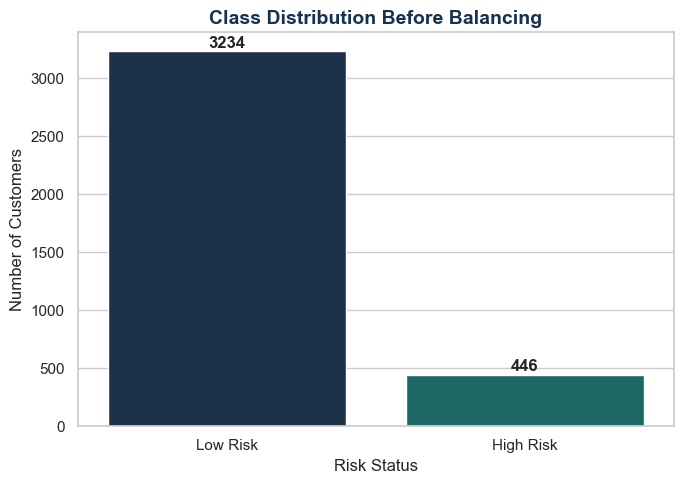

In [13]:

# 📊 Task 13: Class Imbalance Analysis

# Count Target Classes
class_counts = y_train.value_counts().sort_index()

print("Training Class Distribution:")
print(class_counts)

# Visualize Class Distribution
plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Low Risk", "High Risk"],
    y=class_counts.values,
    hue=["Low Risk", "High Risk"],
    palette=["#16324F", "#0F766E"],
    legend=False
)

plt.title("Class Distribution Before Balancing",
          color="#16324F", fontsize=14, fontweight="bold")

plt.xlabel("Risk Status")
plt.ylabel("Number of Customers")

for i, value in enumerate(class_counts.values):
    plt.text(i, value + 30, value, ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


In [14]:

# 📈 Original Baseline Performance

baseline_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

baseline_f1 = f1_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

baseline_probability = logistic_model.predict_proba(
    X_test_model
)[:, 1]

baseline_auc = roc_auc_score(
    y_test, baseline_probability
)

print("BASELINE MODEL PERFORMANCE")
print("-" * 40)

print("High Risk Recall:", round(baseline_recall, 4))
print("High Risk F1-Score:", round(baseline_f1, 4))
print("AUC-ROC:", round(baseline_auc, 4))


BASELINE MODEL PERFORMANCE
----------------------------------------
High Risk Recall: 1.0
High Risk F1-Score: 1.0
AUC-ROC: 1.0



### 📌 Task 14: Apply Balancing Techniques and Retrain the Model

Different sampling techniques are applied to handle class imbalance:

- **Under-Sampling:** Reduces majority class records.
- **Over-Sampling:** Increases minority class records.
- **SMOTE:** Creates synthetic minority class samples.
- **ADASYN:** Generates synthetic samples based on learning difficulty.

The Logistic Regression model is retrained using each technique and evaluated on the original testing dataset.


In [15]:

# 🤖 Task 14: Apply Sampling Techniques and Retrain Models

# Create Preprocessing Function
def create_preprocessor():

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])

    return preprocessor


# Define Sampling Techniques
sampling_methods = {
    "Under-Sampling": RandomUnderSampler(random_state=42),
    "Over-Sampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42)
}

# Store Models and Results
balanced_models = {}
balanced_results = []
sampling_counts = {}

# Train Model with Each Technique
for name, sampler in sampling_methods.items():

    model = ImbPipeline([
        ("preprocessor", create_preprocessor()),
        ("sampler", sampler),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    # Train Model
    model.fit(X_train_model, y_train)

    # Predict Test Data
    predictions = model.predict(X_test_model)

    # Predict Probabilities
    probabilities = model.predict_proba(X_test_model)[:, 1]

    # Calculate Performance Metrics
    recall = recall_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    auc_score = roc_auc_score(y_test, probabilities)

    # Save Model
    balanced_models[name] = model

    # Save Results
    balanced_results.append({
        "Technique": name,
        "Recall": recall,
        "F1-Score": f1,
        "AUC-ROC": auc_score
    })

    # Display Resampled Class Distribution
    transformed_data = model.named_steps["preprocessor"].transform(
        X_train_model
    )

    resampled_X, resampled_y = model.named_steps["sampler"].fit_resample(
        transformed_data, y_train
    )

    sampling_counts[name] = pd.Series(resampled_y).value_counts().to_dict()

    print("\nTechnique:", name)
    print("Before Balancing:")
    print(y_train.value_counts().to_dict())

    print("After Balancing:")
    print(pd.Series(resampled_y).value_counts().to_dict())

print("\nAll Four Models Trained Successfully!")



Technique: Under-Sampling
Before Balancing:
{0: 3234, 1: 446}
After Balancing:
{0: 446, 1: 446}

Technique: Over-Sampling
Before Balancing:
{0: 3234, 1: 446}
After Balancing:
{0: 3234, 1: 3234}

Technique: SMOTE
Before Balancing:
{0: 3234, 1: 446}
After Balancing:
{0: 3234, 1: 3234}

Technique: ADASYN
Before Balancing:
{0: 3234, 1: 446}
After Balancing:
{1: 3239, 0: 3234}

All Four Models Trained Successfully!


In [16]:

# 📊 Display Balanced Model Results

balanced_df = pd.DataFrame(balanced_results)

print("BALANCED MODEL PERFORMANCE")
print("-" * 50)

print(balanced_df.round(4).to_string(index=False))


BALANCED MODEL PERFORMANCE
--------------------------------------------------
     Technique  Recall  F1-Score  AUC-ROC
Under-Sampling     1.0    0.9867      1.0
 Over-Sampling     1.0    0.9911      1.0
         SMOTE     1.0    0.9911      1.0
        ADASYN     1.0    0.9867      1.0



### 📌 Task 15: Compare Performance Before and After Balancing

The baseline Logistic Regression model is compared with all four balanced models using minority class Recall, F1-Score and AUC-ROC. This comparison helps identify which balancing technique improves High Risk customer detection.


In [17]:

# 📈 Task 15: Compare Before and After Balancing

# Create Baseline Result
baseline_result = pd.DataFrame([{
    "Technique": "Baseline",
    "Recall": baseline_recall,
    "F1-Score": baseline_f1,
    "AUC-ROC": baseline_auc
}])

# Combine All Results
comparison_df = pd.concat(
    [baseline_result, balanced_df],
    ignore_index=True
)

# Display Comparison Table
print("BASELINE vs BALANCED MODEL COMPARISON")
print("=" * 60)

print(comparison_df.round(4).to_string(index=False))


BASELINE vs BALANCED MODEL COMPARISON
     Technique  Recall  F1-Score  AUC-ROC
      Baseline     1.0    1.0000      1.0
Under-Sampling     1.0    0.9867      1.0
 Over-Sampling     1.0    0.9911      1.0
         SMOTE     1.0    0.9911      1.0
        ADASYN     1.0    0.9867      1.0


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_004.png


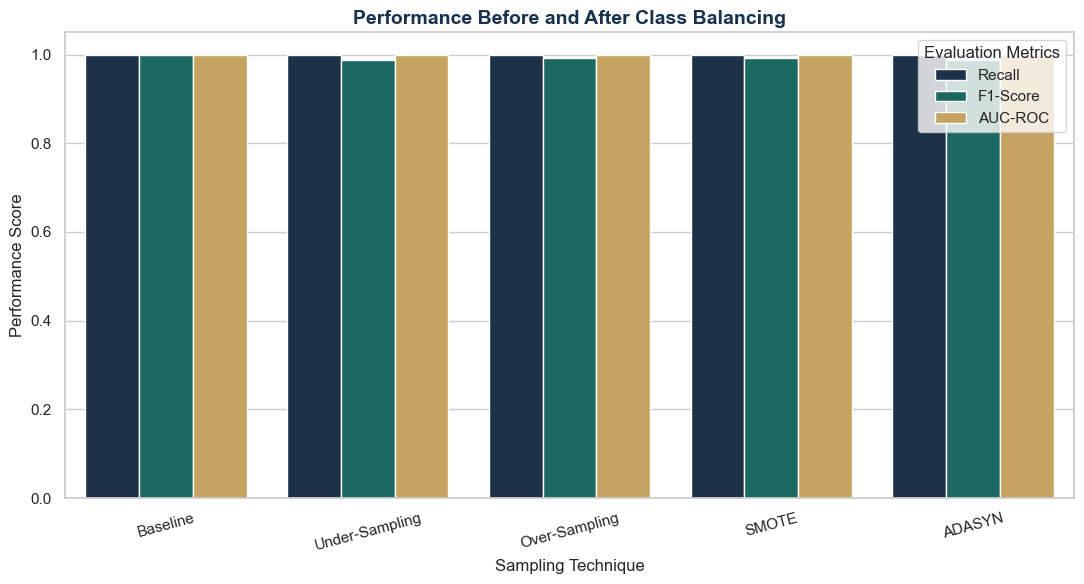

In [18]:

# 📊 Visualize Performance Comparison

comparison_plot = comparison_df.melt(
    id_vars="Technique",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_plot,
    x="Technique",
    y="Score",
    hue="Metric",
    palette={
        "Recall": "#16324F",
        "F1-Score": "#0F766E",
        "AUC-ROC": "#D6A84F"
    }
)

plt.title(
    "Performance Before and After Class Balancing",
    color="#16324F",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Sampling Technique")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)

plt.legend(title="Evaluation Metrics")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [19]:

# 🏆 Identify Best Balancing Technique

best_model_index = balanced_df["F1-Score"].idxmax()

best_technique = balanced_df.loc[
    best_model_index, "Technique"
]

best_f1_score = balanced_df.loc[
    best_model_index, "F1-Score"
]

print("BEST BALANCING TECHNIQUE")
print("-" * 40)

print("Technique:", best_technique)
print("F1-Score:", round(best_f1_score, 4))

print("\nComparison Completed Successfully!")


BEST BALANCING TECHNIQUE
----------------------------------------
Technique: Over-Sampling
F1-Score: 0.9911

Comparison Completed Successfully!



### 📝 PART D: CONCLUSION

In this part, we demonstrated the impact of class imbalance on classification performance. We applied Under-Sampling, Over-Sampling, SMOTE and ADASYN techniques and retrained Logistic Regression models. Their performance was compared using minority class Recall, F1-Score and AUC-ROC.



# ✅ PART D COMPLETED SUCCESSFULLY

**Tasks Completed:** 13, 14 and 15

**Balancing Techniques:** 4

**Model:** Logistic Regression

**Next:** 🤖 Part E – Two-Baseline Classification Models

---



# 🌳 PART E: TREE-BASED CLASSIFICATION MODELS

---

**🎯 Objective:**

Implement Decision Tree and Random Forest classifiers to predict customer risk status and compare their performance.

**🤖 Models:**
- Decision Tree Classifier
- Random Forest Classifier

**📌 Total Tasks:** 4 (Task 16, 17, 18 and 19)

---



### 📌 Task 16: Implement Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm that makes predictions using a tree-like structure of decision rules. It divides data into smaller groups based on feature values and predicts the final class.


In [20]:

# 🌳 Task 16: Decision Tree Classifier

# Prepare Training and Testing Data
X_train_tree = X_train_prepared.drop(
    columns=["last_transaction_date"],
    errors="ignore"
)

X_test_tree = X_test_prepared.drop(
    columns=["last_transaction_date"],
    errors="ignore"
)

# Identify Numerical and Categorical Features
tree_num_columns = X_train_tree.select_dtypes(
    include=np.number
).columns.tolist()

tree_cat_columns = X_train_tree.select_dtypes(
    exclude=np.number
).columns.tolist()

# Create Preprocessing Pipeline
def create_tree_preprocessor():

    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    cat_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", num_pipeline, tree_num_columns),
        ("cat", cat_pipeline, tree_cat_columns)
    ])

# Create Decision Tree Model
decision_tree_model = Pipeline([
    ("preprocessor", create_tree_preprocessor()),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train Model
decision_tree_model.fit(X_train_tree, y_train)

# Make Predictions
dt_train_pred = decision_tree_model.predict(X_train_tree)
dt_test_pred = decision_tree_model.predict(X_test_tree)

print("Decision Tree Model Trained Successfully!")
print("Training Records:", X_train_tree.shape[0])
print("Testing Records:", X_test_tree.shape[0])


Decision Tree Model Trained Successfully!
Training Records: 3680
Testing Records: 920



### 📌 Task 17: Analyze Overfitting by Comparing Training and Testing Performance

Overfitting occurs when a model performs very well on training data but poorly on unseen testing data. Training and testing accuracy are compared to understand how well the Decision Tree model generalizes to new data.


In [21]:

# 📊 Task 17: Analyze Decision Tree Overfitting

# Calculate Training Accuracy
dt_train_accuracy = accuracy_score(
    y_train, dt_train_pred
)

# Calculate Testing Accuracy
dt_test_accuracy = accuracy_score(
    y_test, dt_test_pred
)

# Calculate Accuracy Difference
dt_accuracy_gap = dt_train_accuracy - dt_test_accuracy

print("DECISION TREE PERFORMANCE")
print("-" * 40)

print("Training Accuracy:", round(dt_train_accuracy, 4))
print("Testing Accuracy :", round(dt_test_accuracy, 4))
print("Accuracy Gap     :", round(dt_accuracy_gap, 4))

# Analyze Overfitting
if dt_accuracy_gap > 0.10:
    print("\nResult: Possible Overfitting Detected.")

elif dt_accuracy_gap > 0.05:
    print("\nResult: Moderate Difference Between Training and Testing.")

else:
    print("\nResult: Good Training and Testing Accuracy Balance.")


DECISION TREE PERFORMANCE
----------------------------------------
Training Accuracy: 1.0
Testing Accuracy : 0.9739
Accuracy Gap     : 0.0261

Result: Good Training and Testing Accuracy Balance.


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_005.png


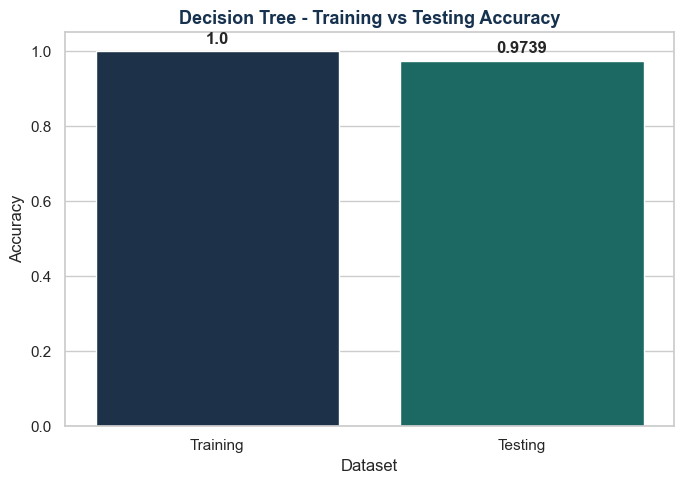

In [22]:

# 📈 Decision Tree Training vs Testing Accuracy

dt_accuracy_data = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [dt_train_accuracy, dt_test_accuracy]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=dt_accuracy_data,
    x="Dataset",
    y="Accuracy",
    hue="Dataset",
    palette=["#16324F", "#0F766E"],
    legend=False
)

plt.title(
    "Decision Tree - Training vs Testing Accuracy",
    color="#16324F",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

for i, value in enumerate(dt_accuracy_data["Accuracy"]):
    plt.text(i, value + 0.02, round(value, 4),
             ha="center", fontweight="bold")

plt.tight_layout()
plt.show()



### 📌 Task 18: Implement Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to make predictions. It improves model stability and reduces overfitting by combining predictions from different trees.


In [23]:

# 🌳 Task 18: Random Forest Classifier

# Create Random Forest Model
random_forest_model = Pipeline([
    ("preprocessor", create_tree_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Model
random_forest_model.fit(X_train_tree, y_train)

# Make Predictions
rf_train_pred = random_forest_model.predict(X_train_tree)
rf_test_pred = random_forest_model.predict(X_test_tree)

print("Random Forest Model Trained Successfully!")
print("Number of Trees: 100")
print("Training Records:", X_train_tree.shape[0])
print("Testing Records:", X_test_tree.shape[0])


Random Forest Model Trained Successfully!
Number of Trees: 100
Training Records: 3680
Testing Records: 920


In [24]:

# 📊 Random Forest Training and Testing Accuracy

rf_train_accuracy = accuracy_score(
    y_train, rf_train_pred
)

rf_test_accuracy = accuracy_score(
    y_test, rf_test_pred
)

rf_accuracy_gap = rf_train_accuracy - rf_test_accuracy

print("RANDOM FOREST PERFORMANCE")
print("-" * 40)

print("Training Accuracy:", round(rf_train_accuracy, 4))
print("Testing Accuracy :", round(rf_test_accuracy, 4))
print("Accuracy Gap     :", round(rf_accuracy_gap, 4))


RANDOM FOREST PERFORMANCE
----------------------------------------
Training Accuracy: 1.0
Testing Accuracy : 0.9978
Accuracy Gap     : 0.0022



### 📌 Task 19: Compare Decision Tree vs Random Forest

Decision Tree and Random Forest are compared using training accuracy, testing accuracy, and accuracy gap. A smaller accuracy gap indicates a better balance between training performance and generalization to unseen data.


In [25]:

# 📊 Task 19: Compare Decision Tree and Random Forest

model_comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],

    "Training Accuracy": [
        dt_train_accuracy,
        rf_train_accuracy
    ],

    "Testing Accuracy": [
        dt_test_accuracy,
        rf_test_accuracy
    ],

    "Accuracy Gap": [
        dt_accuracy_gap,
        rf_accuracy_gap
    ]
})

print("DECISION TREE vs RANDOM FOREST")
print("=" * 65)

print(model_comparison.round(4).to_string(index=False))


DECISION TREE vs RANDOM FOREST
        Model  Training Accuracy  Testing Accuracy  Accuracy Gap
Decision Tree                1.0            0.9739        0.0261
Random Forest                1.0            0.9978        0.0022


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_006.png


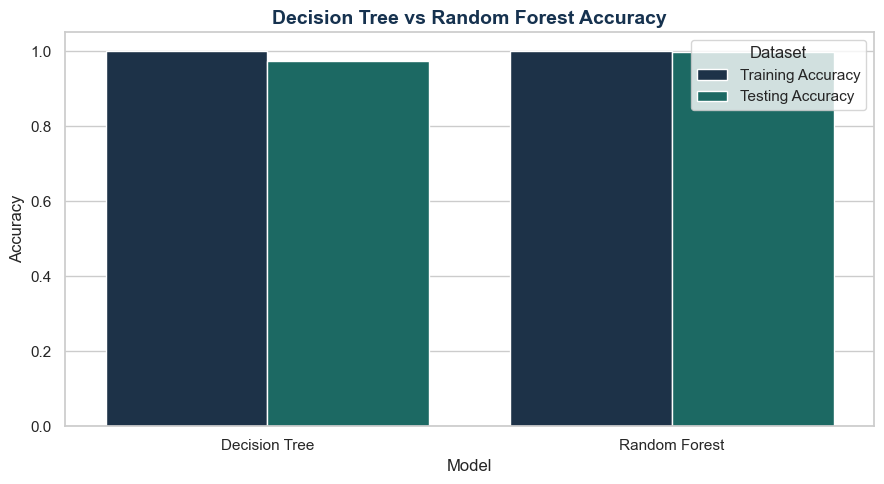

In [26]:

# 📈 Visualize Model Comparison

comparison_accuracy = model_comparison.melt(
    id_vars="Model",
    value_vars=["Training Accuracy", "Testing Accuracy"],
    var_name="Dataset",
    value_name="Accuracy"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_accuracy,
    x="Model",
    y="Accuracy",
    hue="Dataset",
    palette=["#16324F", "#0F766E"]
)

plt.title(
    "Decision Tree vs Random Forest Accuracy",
    color="#16324F",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.legend(title="Dataset")
plt.tight_layout()
plt.show()


In [27]:

# 🏆 Generalization Comparison

best_generalization = model_comparison.loc[
    model_comparison["Accuracy Gap"].abs().idxmin()
]

best_testing_model = model_comparison.loc[
    model_comparison["Testing Accuracy"].idxmax()
]

print("BEST GENERALIZATION:")
print(best_generalization["Model"])
print("Accuracy Gap:", round(
    best_generalization["Accuracy Gap"], 4
))

print("\nBEST TESTING ACCURACY:")
print(best_testing_model["Model"])
print("Testing Accuracy:", round(
    best_testing_model["Testing Accuracy"], 4
))


BEST GENERALIZATION:
Random Forest
Accuracy Gap: 0.0022

BEST TESTING ACCURACY:
Random Forest
Testing Accuracy: 0.9978



### 📝 PART E: CONCLUSION

In this part, we implemented Decision Tree and Random Forest classifiers. We analyzed overfitting by comparing training and testing accuracy and evaluated both models based on accuracy and generalization. Random Forest combines multiple Decision Trees to improve prediction stability.



# ✅ PART E COMPLETED SUCCESSFULLY

**Tasks Completed:** 16, 17, 18 and 19

**Models Implemented:**
- Decision Tree Classifier
- Random Forest Classifier

**Next:** 🎯 Part F – Hyperparameter Tuning

---



# 🔧 PART F: HYPERPARAMETER TUNING

---

**🎯 Objective:**

Optimize machine learning model parameters using RandomizedSearchCV and GridSearchCV to improve classification performance.

**🤖 Models:**
- Decision Tree Classifier
- Random Forest Classifier

**📌 Total Tasks:** 3 (Task 20, 21 and 22)

---



### 📌 Task 20: Apply Randomized Search CV to Optimize Model Hyperparameters

RandomizedSearchCV tests different combinations of hyperparameters to find better model settings. It is applied to Decision Tree and Random Forest classifiers to identify their best parameter combinations using cross-validation.


In [28]:

# 🌳 Randomized Search CV - Decision Tree

dt_parameters = {
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__criterion": ["gini", "entropy"],
    "classifier__class_weight": [None, "balanced"]
}

dt_random_search = RandomizedSearchCV(
    estimator=decision_tree_model,
    param_distributions=dt_parameters,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1
)

# Train Randomized Search
dt_random_search.fit(X_train_tree, y_train)

print("Decision Tree Randomized Search Completed!")

print("\nBest Parameters:")
print(dt_random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(dt_random_search.best_score_, 4))


Decision Tree Randomized Search Completed!

Best Parameters:
{'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 10, 'classifier__criterion': 'gini', 'classifier__class_weight': None}

Best Cross-Validation F1-Score:
0.8894


In [29]:

# 🌲 Randomized Search CV - Random Forest

rf_parameters = {
    "classifier__n_estimators": [100, 150, 200, 300],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2", None],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"]
}

rf_random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_parameters,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1
)

# Train Randomized Search
rf_random_search.fit(X_train_tree, y_train)

print("Random Forest Randomized Search Completed!")

print("\nBest Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(rf_random_search.best_score_, 4))


Random Forest Randomized Search Completed!

Best Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20, 'classifier__class_weight': 'balanced_subsample'}

Best Cross-Validation F1-Score:
0.9606


In [30]:

# 📊 Compare Randomized Search Results

random_search_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Best CV F1-Score": [
        dt_random_search.best_score_,
        rf_random_search.best_score_
    ]
})

print("RANDOMIZED SEARCH COMPARISON")
print("-" * 45)

print(random_search_results.round(4).to_string(index=False))

# Select Best Performing Model
if dt_random_search.best_score_ >= rf_random_search.best_score_:

    best_random_search = dt_random_search
    best_model_name = "Decision Tree"

else:

    best_random_search = rf_random_search
    best_model_name = "Random Forest"

print("\nBest Performing Model:", best_model_name)
print("Best CV F1-Score:", round(
    best_random_search.best_score_, 4
))


RANDOMIZED SEARCH COMPARISON
---------------------------------------------
        Model  Best CV F1-Score
Decision Tree            0.8894
Random Forest            0.9606

Best Performing Model: Random Forest
Best CV F1-Score: 0.9606



### 📌 Task 21: Apply Grid Search CV for Fine-Tuning the Best Performing Model

GridSearchCV evaluates all specified combinations of hyperparameters to find the best model settings. The best-performing model identified through RandomizedSearchCV is fine-tuned using a smaller parameter grid and cross-validation.


In [31]:

# 🔧 Task 21: Grid Search CV

# Get Best Parameters from Randomized Search
best_parameters = best_random_search.best_params_

# Create a Smaller Parameter Grid
if best_model_name == "Decision Tree":

    grid_parameters = {
        "classifier__max_depth": [
            best_parameters["classifier__max_depth"],
            5, 10, 15
        ],
        "classifier__min_samples_split": [
            best_parameters["classifier__min_samples_split"],
            2, 5
        ],
        "classifier__min_samples_leaf": [
            best_parameters["classifier__min_samples_leaf"],
            1, 2
        ]
    }

else:

    grid_parameters = {
        "classifier__n_estimators": [
            best_parameters["classifier__n_estimators"],
            100, 200
        ],
        "classifier__max_depth": [
            best_parameters["classifier__max_depth"],
            10, 20
        ],
        "classifier__min_samples_leaf": [
            best_parameters["classifier__min_samples_leaf"],
            1, 2
        ]
    }

# Apply Grid Search
grid_search = GridSearchCV(
    estimator=best_random_search.best_estimator_,
    param_grid=grid_parameters,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

# Train Grid Search
grid_search.fit(X_train_tree, y_train)

print("Grid Search Completed Successfully!")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(grid_search.best_score_, 4))


Grid Search Completed Successfully!

Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}

Best Cross-Validation F1-Score:
0.9643


In [32]:

# 🤖 Save Final Tuned Model

tuned_model = grid_search.best_estimator_

print("Best Model:", best_model_name)
print("Tuned Model Ready Successfully!")


Best Model: Random Forest
Tuned Model Ready Successfully!



### 📌 Task 22: Compare Tuned vs Untuned Model Performance

The original model and the hyperparameter-tuned model are evaluated on the same testing dataset. Accuracy, Precision, Recall, F1-Score and AUC-ROC are compared to understand the impact of hyperparameter tuning on model performance.


In [33]:

# 📊 Task 22: Compare Tuned and Untuned Models

# Select Original Untuned Model
if best_model_name == "Decision Tree":

    untuned_model = decision_tree_model

else:

    untuned_model = random_forest_model

# Make Untuned Predictions
untuned_pred = untuned_model.predict(X_test_tree)

untuned_prob = untuned_model.predict_proba(
    X_test_tree
)[:, 1]

# Make Tuned Predictions
tuned_pred = tuned_model.predict(X_test_tree)

tuned_prob = tuned_model.predict_proba(
    X_test_tree
)[:, 1]

# Calculate Performance Metrics
comparison_results = pd.DataFrame({
    "Model": ["Untuned Model", "Tuned Model"],

    "Accuracy": [
        accuracy_score(y_test, untuned_pred),
        accuracy_score(y_test, tuned_pred)
    ],

    "Precision": [
        precision_score(y_test, untuned_pred, zero_division=0),
        precision_score(y_test, tuned_pred, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, untuned_pred, zero_division=0),
        recall_score(y_test, tuned_pred, zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, untuned_pred, zero_division=0),
        f1_score(y_test, tuned_pred, zero_division=0)
    ],

    "AUC-ROC": [
        roc_auc_score(y_test, untuned_prob),
        roc_auc_score(y_test, tuned_prob)
    ]
})

print("UNTUNED vs TUNED MODEL PERFORMANCE")
print("=" * 70)

print(comparison_results.round(4).to_string(index=False))


UNTUNED vs TUNED MODEL PERFORMANCE
        Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Untuned Model    0.9978     1.0000   0.982    0.9909   0.9999
  Tuned Model    0.9967     0.9909   0.982    0.9864   0.9999


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_007.png


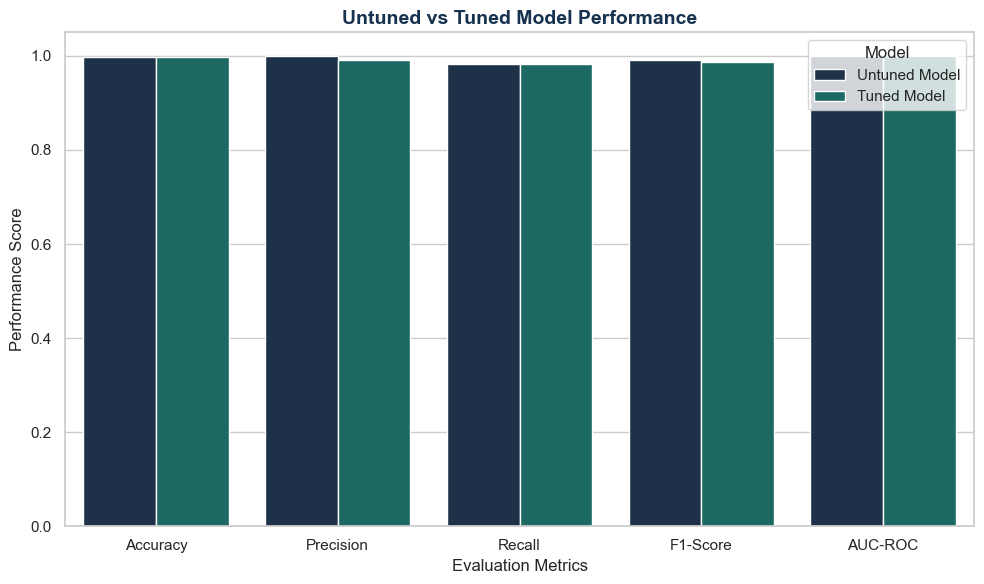

In [34]:

# 📈 Visualize Tuned vs Untuned Performance

performance_plot = comparison_results.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=performance_plot,
    x="Metric",
    y="Score",
    hue="Model",
    palette=["#16324F", "#0F766E"]
)

plt.title(
    "Untuned vs Tuned Model Performance",
    color="#16324F",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)

plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [35]:

# 🏆 Check Hyperparameter Tuning Improvement

untuned_f1 = comparison_results.loc[
    0, "F1-Score"
]

tuned_f1 = comparison_results.loc[
    1, "F1-Score"
]

print("HYPERPARAMETER TUNING ANALYSIS")
print("-" * 45)

print("Selected Model:", best_model_name)
print("Untuned F1-Score:", round(untuned_f1, 4))
print("Tuned F1-Score:", round(tuned_f1, 4))

if tuned_f1 > untuned_f1:

    print("\nResult: Tuning improved the F1-Score.")

elif tuned_f1 < untuned_f1:

    print("\nResult: Untuned model performed better.")

else:

    print("\nResult: Both models achieved the same F1-Score.")


HYPERPARAMETER TUNING ANALYSIS
---------------------------------------------
Selected Model: Random Forest
Untuned F1-Score: 0.9909
Tuned F1-Score: 0.9864

Result: Untuned model performed better.



### 📝 PART F: CONCLUSION

In this part, we applied RandomizedSearchCV to optimize Decision Tree and Random Forest hyperparameters. We then used GridSearchCV to fine-tune the best-performing model. Finally, we compared tuned and untuned models using classification performance metrics.



# ✅ PART F COMPLETED SUCCESSFULLY

**Tasks Completed:** 20, 21 and 22

**Techniques Used:**
- RandomizedSearchCV
- GridSearchCV

**Model Tuning:** Completed

**Next:** 📈 Part G – Model Evaluation & ROC Analysis

---



# 📈 PART G: MODEL EVALUATION & ROC ANALYSIS

---

**🎯 Objective:**

Evaluate all trained classification models using ROC Curves and AUC-ROC scores and select the best final model based on minimizing False Negative errors.

**📊 Evaluation Metrics:**
- ROC Curve
- AUC-ROC
- False Negative (FN)
- Recall

**📌 Total Tasks:** 3 (Task 23, 24 and 25)

---



### 📌 Task 23: Plot and Interpret ROC Curve for All Models

The ROC Curve represents the relationship between True Positive Rate (TPR) and False Positive Rate (FPR) at different classification thresholds. It helps evaluate how effectively a model distinguishes between Low Risk and High Risk customers.

A curve closer to the top-left corner indicates better classification performance.


In [36]:

# 📊 Task 23: Collect All Trained Models

# Store all models for ROC Analysis
all_models = {
    "Logistic Regression": (
        logistic_model, X_test_model
    ),

    "Decision Tree": (
        decision_tree_model, X_test_tree
    ),

    "Random Forest": (
        random_forest_model, X_test_tree
    ),

    "Tuned Model": (
        tuned_model, X_test_tree
    )
}

# Add Four Balanced Models
for name, model in balanced_models.items():

    all_models[name] = (
        model, X_test_model
    )

print("TOTAL MODELS FOR EVALUATION:", len(all_models))

print("\nModels Included:")

for name in all_models:
    print("-", name)


TOTAL MODELS FOR EVALUATION: 8

Models Included:
- Logistic Regression
- Decision Tree
- Random Forest
- Tuned Model
- Under-Sampling
- Over-Sampling
- SMOTE
- ADASYN


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_008.png


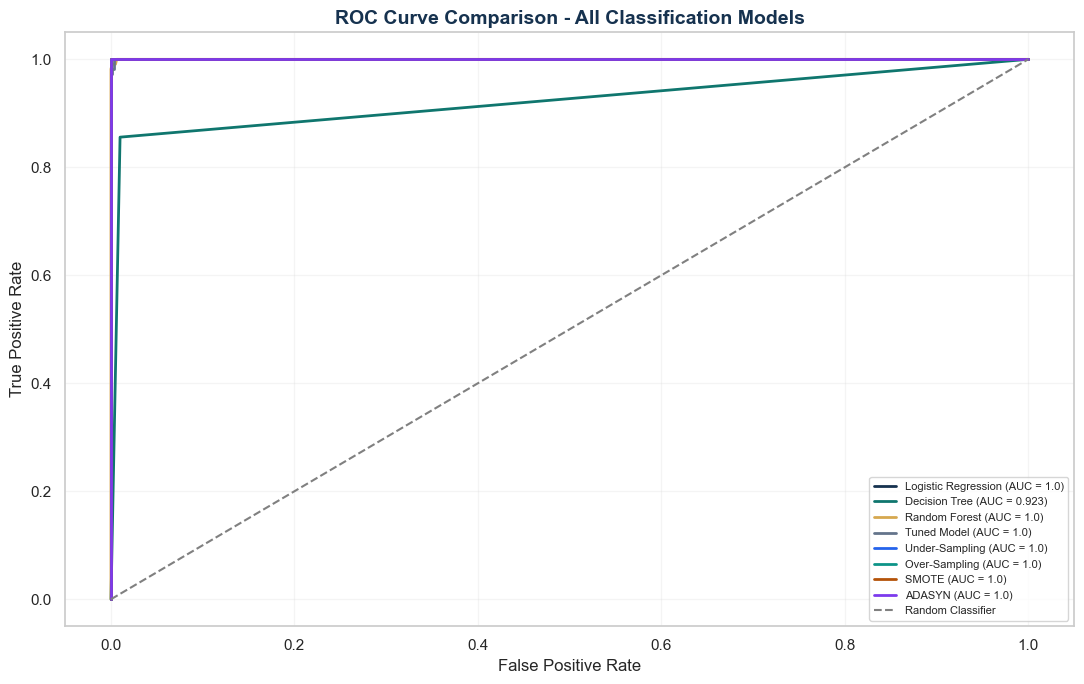

ROC Curves Generated Successfully!


In [37]:

# 📈 Plot ROC Curve for All Models

plt.figure(figsize=(11, 7))

roc_results = []

theme_colors = [
    "#16324F",
    "#0F766E",
    "#D6A84F",
    "#64748B",
    "#2563EB",
    "#0D9488",
    "#B45309",
    "#7C3AED"
]

for i, (name, (model, test_data)) in enumerate(all_models.items()):

    # Predict Probabilities
    probabilities = model.predict_proba(test_data)[:, 1]

    # Calculate ROC Curve
    fpr, tpr, thresholds = roc_curve(
        y_test, probabilities
    )

    # Calculate AUC
    auc_score = roc_auc_score(
        y_test, probabilities
    )

    # Plot ROC Curve
    plt.plot(
        fpr,
        tpr,
        label=name + " (AUC = " + str(round(auc_score, 3)) + ")",
        color=theme_colors[i % len(theme_colors)],
        linewidth=2
    )

    roc_results.append({
        "Model": name,
        "AUC-ROC": auc_score
    })

# Random Classifier Reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title(
    "ROC Curve Comparison - All Classification Models",
    color="#16324F",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("ROC Curves Generated Successfully!")



### 📌 Task 24: Compute and Compare AUC-ROC Scores

AUC-ROC measures the overall ability of a classification model to distinguish between different classes. A higher AUC-ROC score indicates better class separation. All trained models are compared using their AUC-ROC scores to understand their classification performance.


In [38]:

# 📊 Task 24: Compare AUC-ROC Scores

auc_comparison = pd.DataFrame(roc_results)

auc_comparison = auc_comparison.sort_values(
    by="AUC-ROC",
    ascending=False
).reset_index(drop=True)

print("AUC-ROC MODEL COMPARISON")
print("=" * 50)

print(auc_comparison.round(4).to_string(index=False))

print("\nBest AUC-ROC Model:")
print(auc_comparison.iloc[0]["Model"])

print("Best AUC-ROC Score:",
      round(auc_comparison.iloc[0]["AUC-ROC"], 4))


AUC-ROC MODEL COMPARISON
              Model  AUC-ROC
Logistic Regression   1.0000
              SMOTE   1.0000
      Over-Sampling   1.0000
     Under-Sampling   1.0000
             ADASYN   1.0000
      Random Forest   0.9999
        Tuned Model   0.9999
      Decision Tree   0.9230

Best AUC-ROC Model:
Logistic Regression
Best AUC-ROC Score: 1.0


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_009.png


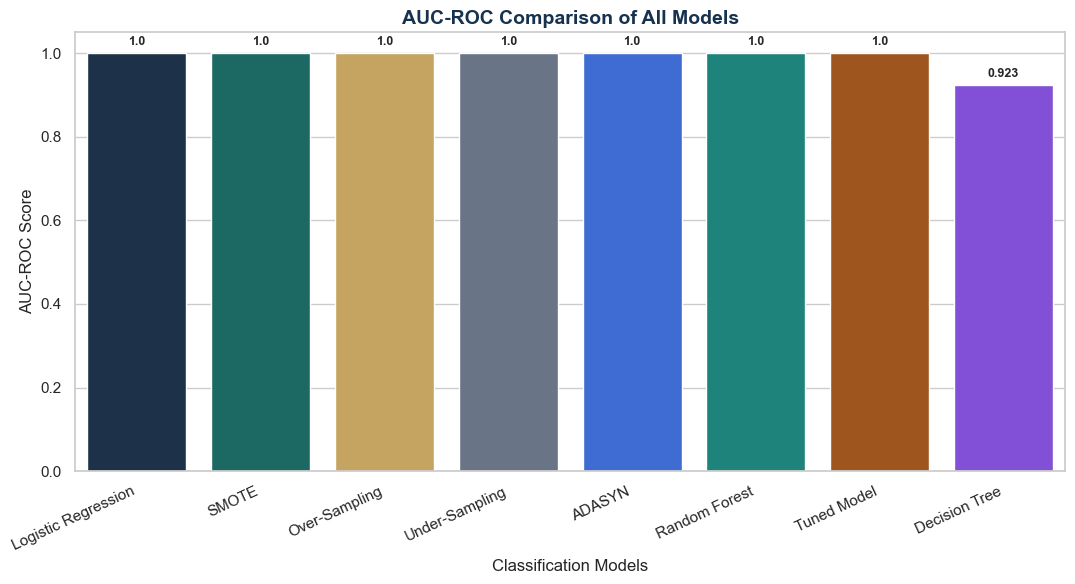

In [39]:

# 📈 Visualize AUC-ROC Comparison

plt.figure(figsize=(11, 6))

sns.barplot(
    data=auc_comparison,
    x="Model",
    y="AUC-ROC",
    hue="Model",
    palette=[
        "#16324F",
        "#0F766E",
        "#D6A84F",
        "#64748B",
        "#2563EB",
        "#0D9488",
        "#B45309",
        "#7C3AED"
    ],
    legend=False
)

plt.title(
    "AUC-ROC Comparison of All Models",
    color="#16324F",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Classification Models")
plt.ylabel("AUC-ROC Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=25, ha="right")

for i, value in enumerate(auc_comparison["AUC-ROC"]):
    plt.text(
        i, value + 0.02,
        round(value, 3),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()



### 📌 Task 25: Select the Best Final Model Based on Business Requirements

In risk prediction, False Negative errors are very important because they represent High Risk customers incorrectly predicted as Low Risk. The final model is selected by minimizing False Negative errors and prioritizing higher Recall. AUC-ROC is also considered when comparing models with similar results.


In [40]:

# 🎯 Task 25: Evaluate All Models Based on Business Requirements

final_evaluation = []

for name, (model, test_data) in all_models.items():

    # Predictions
    predictions = model.predict(test_data)

    # Probability Predictions
    probabilities = model.predict_proba(test_data)[:, 1]

    # Confusion Matrix
    model_cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    TN, FP, FN, TP = model_cm.ravel()

    # Performance Metrics
    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    auc_score = roc_auc_score(y_test, probabilities)

    final_evaluation.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUC-ROC": auc_score,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP
    })

# Create Final Evaluation Table
final_evaluation_df = pd.DataFrame(final_evaluation)

print("FINAL MODEL BUSINESS EVALUATION")
print("=" * 80)

print(
    final_evaluation_df.round(4).to_string(index=False)
)


FINAL MODEL BUSINESS EVALUATION
              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC  TN  FP  FN  TP
Logistic Regression    1.0000     1.0000  1.0000    1.0000   1.0000 809   0   0 111
      Decision Tree    0.9739     0.9223  0.8559    0.8879   0.9230 801   8  16  95
      Random Forest    0.9978     1.0000  0.9820    0.9909   0.9999 809   0   2 109
        Tuned Model    0.9967     0.9909  0.9820    0.9864   0.9999 808   1   2 109
     Under-Sampling    0.9967     0.9737  1.0000    0.9867   1.0000 806   3   0 111
      Over-Sampling    0.9978     0.9823  1.0000    0.9911   1.0000 807   2   0 111
              SMOTE    0.9978     0.9823  1.0000    0.9911   1.0000 807   2   0 111
             ADASYN    0.9967     0.9737  1.0000    0.9867   1.0000 806   3   0 111


In [41]:

# 🏆 Select Best Final Model

# First Priority: Minimum False Negatives
# Second Priority: Maximum Recall
# Third Priority: Maximum AUC-ROC

final_evaluation_df = final_evaluation_df.sort_values(
    by=["FN", "Recall", "AUC-ROC"],
    ascending=[True, False, False]
).reset_index(drop=True)

# Select Best Model
best_final_result = final_evaluation_df.iloc[0]

final_model_name = best_final_result["Model"]

final_model = all_models[final_model_name][0]

final_test_data = all_models[final_model_name][1]

# Save Final Predictions
final_predictions = final_model.predict(final_test_data)

final_probabilities = final_model.predict_proba(
    final_test_data
)[:, 1]

print("🏆 BEST FINAL CLASSIFICATION MODEL")
print("=" * 50)

print("Model:", final_model_name)

print("False Negatives:",
      int(best_final_result["FN"]))

print("False Positives:",
      int(best_final_result["FP"]))

print("Recall:",
      round(best_final_result["Recall"], 4))

print("F1-Score:",
      round(best_final_result["F1-Score"], 4))

print("AUC-ROC:",
      round(best_final_result["AUC-ROC"], 4))

print("\nFinal Model Selected Successfully!")


🏆 BEST FINAL CLASSIFICATION MODEL
Model: Logistic Regression
False Negatives: 0
False Positives: 0
Recall: 1.0
F1-Score: 1.0
AUC-ROC: 1.0

Final Model Selected Successfully!


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_010.png


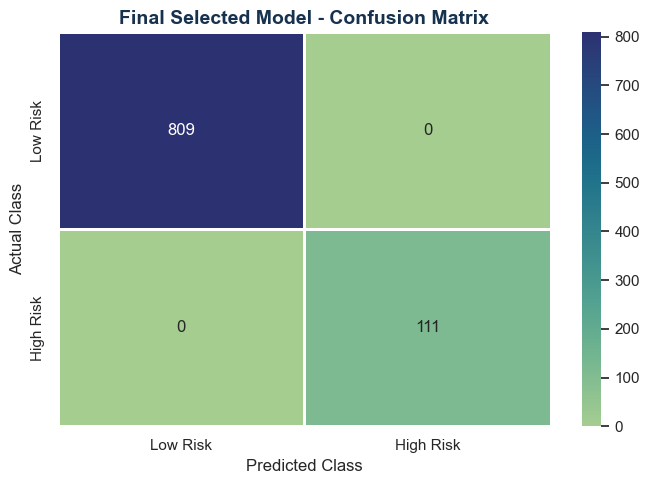

Final Model: Logistic Regression
False Negative Errors: 0


In [42]:

# 📊 Final Selected Model - Confusion Matrix

final_cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="crest",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"],
    linewidths=1
)

plt.title(
    "Final Selected Model - Confusion Matrix",
    color="#16324F",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Final Model:", final_model_name)
print("False Negative Errors:", final_cm[1, 0])



### 📝 PART G: CONCLUSION

In this part, we evaluated all classification models using ROC Curves and AUC-ROC scores. We compared their classification performance and selected the final model based on business requirements, giving priority to minimizing False Negative errors and improving High Risk customer detection.



# ✅ PART G COMPLETED SUCCESSFULLY

**Tasks Completed:** 23, 24 and 25

**Evaluation:** ROC Curve and AUC-ROC

**Final Model:** Selected based on business requirements

**Next:** 📑 Part H – Final Analysis & Reporting

---



# 📑 PART H: FINAL ANALYSIS & REPORTING

---

**🎯 Objective:**

Summarize the complete classification project, evaluate the best-performing model, analyze the impact of class imbalance handling techniques, and interpret model predictions from a business perspective.

**📊 Final Report Includes:**

- Best Classification Model
- Impact of Imbalance Handling
- Performance Metrics Comparison
- Business Interpretation of False Positives and False Negatives

**📌 Total Tasks:** 2 (Task 26 and 27)

---



### 📌 Task 26: Prepare a Final Report

A final report summarizes the performance of all classification models. It identifies the best model based on business requirements, compares evaluation metrics, explains the impact of class balancing techniques, and interprets False Positive and False Negative errors.


In [43]:

# 📊 Task 26: Final Model Summary

# Get Selected Model Information
final_summary = final_evaluation_df.iloc[0]

print("=" * 55)
print("          FINAL CLASSIFICATION MODEL REPORT")
print("=" * 55)

print("\n🏆 BEST FINAL MODEL")
print("Model:", final_model_name)

print("\n📊 PERFORMANCE METRICS")
print("Accuracy :", round(final_summary["Accuracy"], 4))
print("Precision:", round(final_summary["Precision"], 4))
print("Recall   :", round(final_summary["Recall"], 4))
print("F1-Score :", round(final_summary["F1-Score"], 4))
print("AUC-ROC  :", round(final_summary["AUC-ROC"], 4))

print("\n⚠️ ERROR ANALYSIS")
print("False Positives:", int(final_summary["FP"]))
print("False Negatives:", int(final_summary["FN"]))

print("\nFINAL MODEL REPORT GENERATED!")


          FINAL CLASSIFICATION MODEL REPORT

🏆 BEST FINAL MODEL
Model: Logistic Regression

📊 PERFORMANCE METRICS
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0
AUC-ROC  : 1.0

⚠️ ERROR ANALYSIS
False Positives: 0
False Negatives: 0

FINAL MODEL REPORT GENERATED!


In [44]:

# 📊 Compare All Classification Models

report_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC-ROC",
    "FP",
    "FN"
]

final_report_table = final_evaluation_df[
    report_columns
].copy()

print("FINAL MODEL COMPARISON")
print("=" * 85)

print(final_report_table.round(4).to_string(index=False))


FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC  FP  FN
Logistic Regression    1.0000     1.0000  1.0000    1.0000   1.0000   0   0
     Under-Sampling    0.9967     0.9737  1.0000    0.9867   1.0000   3   0
      Over-Sampling    0.9978     0.9823  1.0000    0.9911   1.0000   2   0
              SMOTE    0.9978     0.9823  1.0000    0.9911   1.0000   2   0
             ADASYN    0.9967     0.9737  1.0000    0.9867   1.0000   3   0
      Random Forest    0.9978     1.0000  0.9820    0.9909   0.9999   0   2
        Tuned Model    0.9967     0.9909  0.9820    0.9864   0.9999   1   2
      Decision Tree    0.9739     0.9223  0.8559    0.8879   0.9230   8  16


In [45]:

# ⚖️ Impact of Class Imbalance Handling

# Select Baseline and Balanced Models
imbalance_models = [
    "Logistic Regression",
    "Under-Sampling",
    "Over-Sampling",
    "SMOTE",
    "ADASYN"
]

imbalance_impact = final_evaluation_df[
    final_evaluation_df["Model"].isin(imbalance_models)
][[
    "Model",
    "Recall",
    "F1-Score",
    "AUC-ROC",
    "FP",
    "FN"
]].copy()

print("IMBALANCE HANDLING IMPACT")
print("=" * 75)

print(imbalance_impact.round(4).to_string(index=False))


IMBALANCE HANDLING IMPACT
              Model  Recall  F1-Score  AUC-ROC  FP  FN
Logistic Regression     1.0    1.0000      1.0   0   0
     Under-Sampling     1.0    0.9867      1.0   3   0
      Over-Sampling     1.0    0.9911      1.0   2   0
              SMOTE     1.0    0.9911      1.0   2   0
             ADASYN     1.0    0.9867      1.0   3   0


Successfully Saved: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots\Plot_011.png


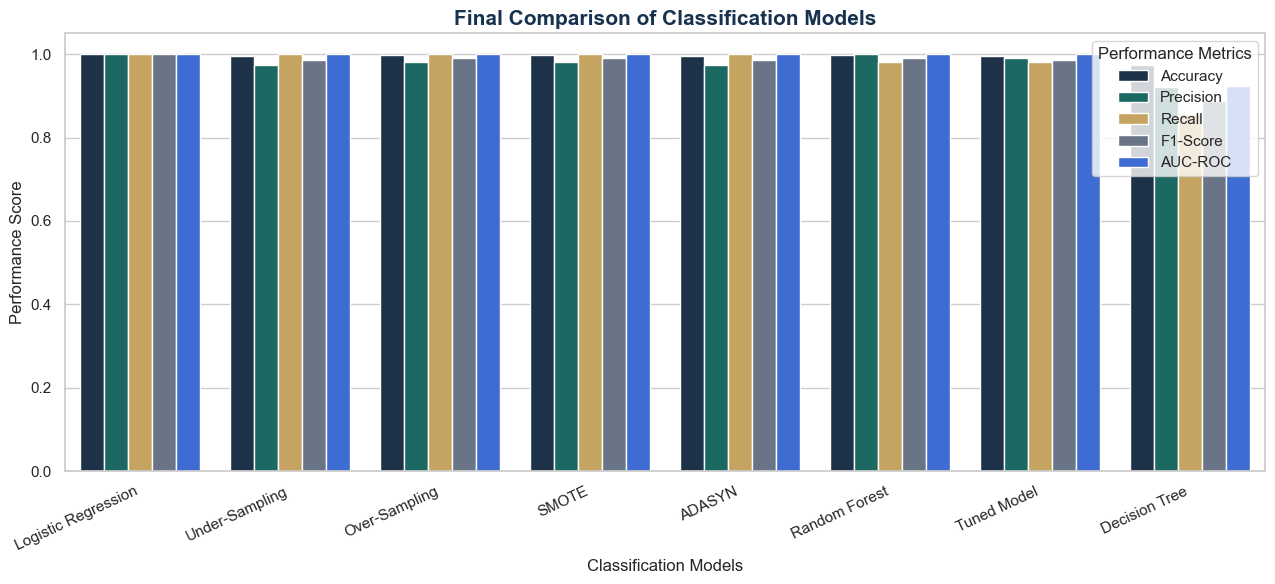

In [46]:

# 📈 Final Classification Performance Visualization

report_plot = final_report_table.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=report_plot,
    x="Model",
    y="Score",
    hue="Metric",
    palette=[
        "#16324F",
        "#0F766E",
        "#D6A84F",
        "#64748B",
        "#2563EB"
    ]
)

plt.title(
    "Final Comparison of Classification Models",
    color="#16324F",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Classification Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=25, ha="right")
plt.legend(title="Performance Metrics")

plt.tight_layout()
plt.show()


In [47]:

# 💼 Business Interpretation of False Positives and False Negatives

final_fp = int(final_summary["FP"])
final_fn = int(final_summary["FN"])

print("BUSINESS INTERPRETATION")
print("=" * 55)

print("\n1. FALSE POSITIVE (Type-I Error)")
print("Count:", final_fp)
print("A Low Risk customer is incorrectly classified as High Risk.")
print("Business Impact: Unnecessary verification, additional checks")
print("and possible inconvenience to genuine customers.")

print("\n2. FALSE NEGATIVE (Type-II Error)")
print("Count:", final_fn)
print("A High Risk customer is incorrectly classified as Low Risk.")
print("Business Impact: Risky customers may go undetected,")
print("potentially causing financial losses.")

print("\n3. BUSINESS PRIORITY")
print("Reducing False Negative errors is important")
print("for identifying more High Risk customers.")


BUSINESS INTERPRETATION

1. FALSE POSITIVE (Type-I Error)
Count: 0
A Low Risk customer is incorrectly classified as High Risk.
Business Impact: Unnecessary verification, additional checks
and possible inconvenience to genuine customers.

2. FALSE NEGATIVE (Type-II Error)
Count: 0
A High Risk customer is incorrectly classified as Low Risk.
Business Impact: Risky customers may go undetected,
potentially causing financial losses.

3. BUSINESS PRIORITY
Reducing False Negative errors is important
for identifying more High Risk customers.


In [48]:

# 📝 Final Project Conclusions and Recommendations

print("FINAL CONCLUSIONS")
print("-" * 50)

print("Selected Model:", final_model_name)

print("\nRECOMMENDATIONS:")

if final_fn > 0:
    print("1. Further reduce False Negative errors.")
else:
    print("1. No False Negative errors on the current test dataset.")

print("2. Monitor Recall for High Risk customers.")
print("3. Compare Precision and Recall before deployment.")
print("4. Monitor model performance on new customer data.")
print("5. Re-evaluate the model periodically.")

print("\nPROJECT ANALYSIS COMPLETED!")


FINAL CONCLUSIONS
--------------------------------------------------
Selected Model: Logistic Regression

RECOMMENDATIONS:
1. No False Negative errors on the current test dataset.
2. Monitor Recall for High Risk customers.
3. Compare Precision and Recall before deployment.
4. Monitor model performance on new customer data.
5. Re-evaluate the model periodically.

PROJECT ANALYSIS COMPLETED!



### 📝 PART H: CONCLUSION

In this part, we prepared the final classification report, compared all trained models, analyzed the impact of imbalance handling techniques, and interpreted False Positive and False Negative errors. We also identified the final model and prepared business recommendations for customer risk prediction.



### 📌 Task 27: Submit Project Deliverables

The complete project is submitted with all required files and results:

1. Source Code / Jupyter Notebook
2. Evaluation Tables and Plots
3. Working Streamlit Application
4. Final Conclusions and Recommendations

All project files are organized for easy review and presentation.


In [49]:

# 📦 Task 27: Save Final Project Deliverables

import os
import joblib

# Create Output Folder
os.makedirs("Final_Output", exist_ok=True)

# Save Final Model and App Information
feature_columns = list(final_test_data.columns)

model_package = {
    "model": final_model,
    "model_name": final_model_name,
    "feature_columns": feature_columns,
    "training_data": X_train_model[feature_columns].copy()
}

joblib.dump(
    model_package,
    "Final_Output/final_risk_model.pkl"
)

# Save Evaluation Tables
final_report_table.to_csv(
    "Final_Output/final_model_comparison.csv",
    index=False
)

imbalance_impact.to_csv(
    "Final_Output/imbalance_impact.csv",
    index=False
)

auc_comparison.to_csv(
    "Final_Output/auc_roc_comparison.csv",
    index=False
)

# Save Final Predictions
final_predictions_report = pd.DataFrame({
    "Actual Risk": y_test.values,
    "Predicted Risk": final_predictions,
    "High Risk Probability": final_probabilities
})

final_predictions_report.to_csv(
    "Final_Output/final_predictions.csv",
    index=False
)

print("All Final Project Files Saved Successfully!")
print("\nSaved Files:")

for file in os.listdir("Final_Output"):
    print("📄", file)


All Final Project Files Saved Successfully!

Saved Files:
📄 auc_roc_comparison.csv
📄 final_model_comparison.csv
📄 final_predictions.csv
📄 final_risk_model.pkl
📄 imbalance_impact.csv


In [50]:

# ✅ Final Project Submission Checklist

submission_items = [
    "Jupyter Notebook",
    "Final Classification Model",
    "Model Comparison Table",
    "Imbalance Impact Table",
    "AUC-ROC Comparison",
    "Final Predictions",
    "ROC Curve and Evaluation Plots",
    "Streamlit Application",
    "Final Conclusions and Recommendations"
]

print("PROJECT SUBMISSION CHECKLIST")
print("=" * 50)

for item in submission_items:
    print("✅", item)

print("\nProject Deliverables Prepared Successfully!")


PROJECT SUBMISSION CHECKLIST
✅ Jupyter Notebook
✅ Final Classification Model
✅ Model Comparison Table
✅ Imbalance Impact Table
✅ AUC-ROC Comparison
✅ Final Predictions
✅ ROC Curve and Evaluation Plots
✅ Streamlit Application
✅ Final Conclusions and Recommendations

Project Deliverables Prepared Successfully!


In [51]:

# =====================================================
# 📊 PROJECT 3 - FINAL PLOT SAVING SYSTEM
# =====================================================

import matplotlib.pyplot as plt
import os

# Exact Project Folder
project_root = r"D:\Supervised Learning\Projects\Project 3"

# Plot Folder
plot_folder = os.path.join(
    project_root,
    "Final_Output",
    "All_Plots"
)

# Create Folder
os.makedirs(plot_folder, exist_ok=True)

# Original Matplotlib Show
original_show = plt.show

# Plot Counter
plot_counter = 0

# Save Every Plot Automatically
def save_project_plot(*args, **kwargs):

    global plot_counter

    os.makedirs(plot_folder, exist_ok=True)

    for fig_num in plt.get_fignums():

        fig = plt.figure(fig_num)

        plot_counter += 1

        filename = "Plot_" + str(plot_counter).zfill(3) + ".png"

        filepath = os.path.join(plot_folder, filename)

        fig.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        print("Successfully Saved:", filepath)

    return original_show(*args, **kwargs)


plt.show = save_project_plot

print("PLOT SAVING SYSTEM READY")
print("Folder Exists:", os.path.isdir(plot_folder))
print("Saving Location:", plot_folder)


PLOT SAVING SYSTEM READY
Folder Exists: True
Saving Location: D:\Supervised Learning\Projects\Project 3\Final_Output\All_Plots


In [52]:

# CHECK ALL SAVED PLOTS

files = [
    f for f in os.listdir(plot_folder)
    if f.lower().endswith(".png")
]

print("TOTAL PLOTS:", len(files))

for file in sorted(files):
    print("📊", file)



TOTAL PLOTS: 5
📊 Plot_007.png
📊 Plot_008.png
📊 Plot_009.png
📊 Plot_010.png
📊 Plot_011.png
